In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [5]:
train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')

def clean_review(text):
    text = str(text).lower()
    text = re.sub(r'<br\s*/?>', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

train_data['text'] = train_data['text'].apply(clean_review)
test_data['text'] = test_data['text'].apply(clean_review)

if train_data['label'].dtype == 'object':
    mapping = {'positive': 1, 'negative': 0, '1': 1, '0': 0}
    train_data['label'] = train_data['label'].map(mapping)
    test_data['label'] = test_data['label'].map(mapping)
else:
    train_data['label'] = train_data['label'].astype(int)
    test_data['label'] = test_data['label'].astype(int)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    train_data['text'], train_data['label'],
    test_size=0.15, random_state=42, stratify=train_data['label']
)

X_test_raw = test_data['text']
y_test = test_data['label']

print(f"Train: {len(X_train_raw)} | Val: {len(X_val_raw)} | Test: {len(X_test_raw)}")

Train: 21250 | Val: 3750 | Test: 25000


In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LEN = 200

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<UNK>")
tokenizer.fit_on_texts(X_train_raw)

X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_val_seq = tokenizer.texts_to_sequences(X_val_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

X_train = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print("X_train shape:", X_train.shape)

X_train shape: (21250, 200)


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout

EMBEDDING_DIM = 100

model_scratch = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model_scratch.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_scratch.summary()

history_scratch = model_scratch.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.7581 - loss: 0.4898 - val_accuracy: 0.8376 - val_loss: 0.4092
Epoch 2/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.8733 - loss: 0.3247 - val_accuracy: 0.8624 - val_loss: 0.3425
Epoch 3/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9139 - loss: 0.2334 - val_accuracy: 0.8547 - val_loss: 0.3604
Epoch 4/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9323 - loss: 0.1882 - val_accuracy: 0.8531 - val_loss: 0.4271
Epoch 5/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9493 - loss: 0.1426 - val_accuracy: 0.8379 - val_loss: 0.5230


In [8]:
!wget http://nlp.stanford.edu/data/glove.6B.zip
!unzip -q glove.6B.zip
print("GloVe downloaded and unzipped.")

--2026-05-25 09:15:30--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-05-25 09:15:31--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-05-25 09:15:31--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [9]:
embeddings_dict = {}
with open('glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        vector = np.asarray(values[1:], dtype='float32')
        embeddings_dict[word] = vector

glove_matrix = np.zeros((VOCAB_SIZE, EMBEDDING_DIM))
for word, i in tokenizer.word_index.items():
    if i < VOCAB_SIZE:
        vector = embeddings_dict.get(word)
        if vector is not None:
            glove_matrix[i] = vector

print("Embedding matrix shape:", glove_matrix.shape)

Embedding matrix shape: (10000, 100)


In [10]:
model_glove = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM,
              embeddings_initializer=tf.keras.initializers.Constant(glove_matrix),
              trainable=False),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model_glove.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_glove.summary()

history_glove = model_glove.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.6041 - loss: 0.6647 - val_accuracy: 0.6507 - val_loss: 0.6221
Epoch 2/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.5882 - loss: 0.6736 - val_accuracy: 0.6861 - val_loss: 0.6386
Epoch 3/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.7118 - loss: 0.5678 - val_accuracy: 0.7960 - val_loss: 0.4540
Epoch 4/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.7929 - loss: 0.4529 - val_accuracy: 0.8029 - val_loss: 0.4395
Epoch 5/5
333/333 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8144 - loss: 0.4113 - val_accuracy: 0.8360 - val_loss: 0.3721



Scratch Model -> Loss: 0.6278 | Accuracy: 81.06%
GloVe Model   -> Loss: 0.3886 | Accuracy: 82.66%

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step


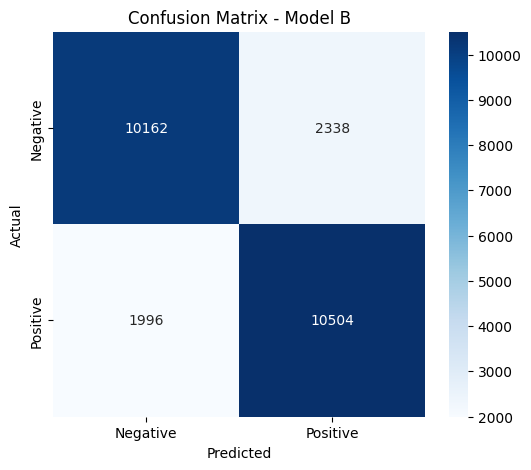


Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.81      0.82     12500
    Positive       0.82      0.84      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



In [11]:
loss_scratch, acc_scratch = model_scratch.evaluate(X_test, y_test, verbose=0)
loss_glove, acc_glove = model_glove.evaluate(X_test, y_test, verbose=0)

print("\n" + "="*40)
print(f"Scratch Model -> Loss: {loss_scratch:.4f} | Accuracy: {acc_scratch*100:.2f}%")
print(f"GloVe Model   -> Loss: {loss_glove:.4f} | Accuracy: {acc_glove*100:.2f}%")
print("="*40 + "\n")

y_pred_probs = model_glove.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype("int32")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Model B')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))